# Лабораторная работа № 3
## DBSCAN


Исходно 48; исключены Cairo, Jakarta; в анализе: 46


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"
71,0.75,5,2,9,0.8043,0.5234,"[18, 19]"
72,0.80,5,2,9,0.8043,0.5234,"[18, 19]"
73,0.85,5,2,9,0.8043,0.5234,"[18, 19]"
105,0.90,6,2,9,0.8043,0.5176,"[19, 18]"
106,0.95,6,2,9,0.8043,0.5176,"[19, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
41,0.80,4,2,8,0.8261,0.5120,"[19, 19]"
74,0.90,5,2,8,0.8261,0.5120,"[19, 19]"


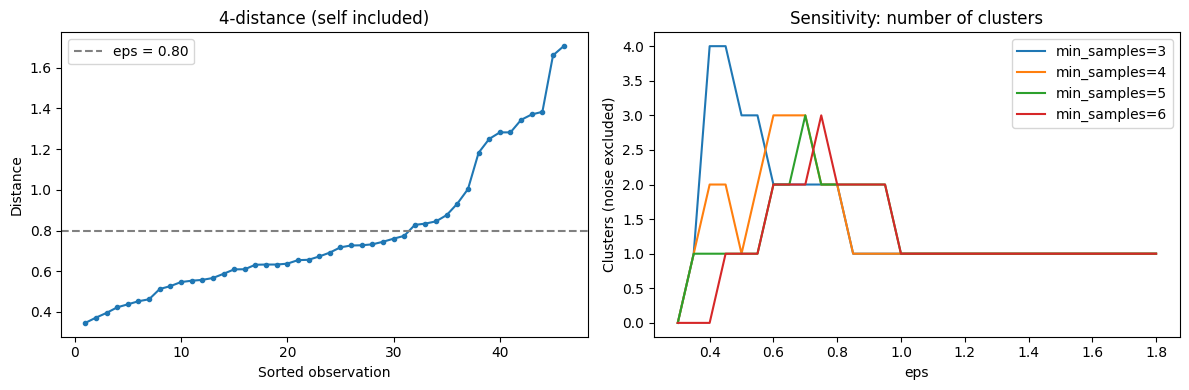

DBSCAN_RESULT: {'eps': 0.8, 'min_samples': 4, 'clusters': 2, 'noise': 8, 'coverage': np.float64(0.8260869565217391), 'silhouette_without_noise': np.float64(0.5120134885325117), 'sizes': '[19, 19]'}


,Cities,Work,Price,Salary
DBSCAN,,,,
-1,8,1900.38,99.92,61.26
1,19,1792.00,77.53,55.16
2,19,1959.21,50.12,14.79


Шум (8): Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo, Zurich
Кластер 1 (19): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna
Кластер 2 (19): Athens, Bogota, Bombay, Buenos Aires, Caracas, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Tel Aviv


In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree

from pathlib import Path

# Используем те же полные наблюдения и стандартизацию для сопоставимости методов.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab3/Econom_Cities_data.csv"
raw3 = pd.read_csv('Econom_Cities_data.csv' if Path('Econom_Cities_data.csv').exists() else DATA_URL, sep=';', decimal=',', na_values=[-9999])
features3 = ['Work', 'Price', 'Salary']
cities3 = raw3.dropna(subset=features3).copy().reset_index(drop=True)
X3 = StandardScaler().fit_transform(cities3[features3])
assert len(cities3)==46
print('Исходно 48; исключены Cairo, Jakarta; в анализе:', len(cities3))

# DBSCAN соединяет плотностно связанные ядра; граничные точки присоединяет к ним.
# eps — радиус соседства; min_samples включает саму точку; метка -1 означает шум.
def db_metrics(eps, min_samples):
    lab = DBSCAN(eps=float(eps), min_samples=int(min_samples)).fit_predict(X3)
    keep = lab != -1
    n_clusters = len(set(lab[keep]))
    # Шум не является отдельным кластером: силуэт считаем только на оставшихся точках.
    score = silhouette_score(X3[keep], lab[keep]) if 2 <= n_clusters < keep.sum() else np.nan
    counts = pd.Series(lab[keep]).value_counts().sort_index().tolist()
    return {'eps':float(eps), 'min_samples':int(min_samples), 'clusters':n_clusters,
            'noise':int((~keep).sum()), 'coverage':keep.mean(),
            'silhouette_without_noise':score, 'sizes':str(counts)}

# Исследуем сетку параметров; для содержательной сегментации требуем покрытие не ниже 80%.
# Это аналитическое ограничение, а не свойство DBSCAN; варианты с большим шумом сохраняем в сетке.
db_grid = pd.DataFrame([db_metrics(ep, ms) for ms in [3,4,5,6]
                        for ep in np.round(np.arange(.30,1.81,.05),2)])
valid_db = db_grid[(db_grid.clusters>=2)&(db_grid.coverage>=.8)]
display(valid_db.sort_values(['silhouette_without_noise','coverage'], ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Четвёртая точка в kneighbors включает сам объект; график помогает оценить масштаб eps.
neigh_dist = NearestNeighbors(n_neighbors=4).fit(X3).kneighbors(X3)[0][:,-1]
axes[0].plot(np.arange(1,len(X3)+1), np.sort(neigh_dist), 'o-', markersize=3)
axes[0].axhline(.8, color='grey', linestyle='--', label='eps = 0.80')
axes[0].set(title='4-distance (self included)', xlabel='Sorted observation', ylabel='Distance')
axes[0].legend()
for ms in [3,4,5,6]:
    part = db_grid[db_grid.min_samples.eq(ms)]
    axes[1].plot(part.eps, part.clusters, label=f'min_samples={ms}')
axes[1].set(title='Sensitivity: number of clusters', xlabel='eps', ylabel='Clusters (noise excluded)')
axes[1].legend(); plt.tight_layout(); plt.show()

# Осознанный компромисс: 38 городов в двух группах при min_samples=d+1.
db_eps, db_min_samples = .8, 4
db_model = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit(X3)
db_raw_labels = db_model.labels_
keep3 = db_raw_labels != -1
order3 = cities3.assign(temp=db_raw_labels).loc[keep3].groupby('temp').Salary.mean().sort_values(ascending=False).index
map3 = {int(old):new+1 for new,old in enumerate(order3)}
db_labels = np.array([map3[int(c)] if c!=-1 else -1 for c in db_raw_labels])
cities3['DBSCAN'] = db_labels
is_core3 = np.zeros(len(X3), dtype=bool)
is_core3[db_model.core_sample_indices_] = True
cities3['Point_type'] = np.where(db_labels==-1,'noise',np.where(is_core3,'core','border'))
db_selected = db_metrics(db_eps, db_min_samples)
print('DBSCAN_RESULT:', db_selected)
db_summary = cities3.groupby('DBSCAN').agg(
    Cities=('City','size'), Work=('Work','mean'), Price=('Price','mean'), Salary=('Salary','mean'))
display(db_summary.round(2))
for c, part in cities3.groupby('DBSCAN'):
    print(('Шум' if c==-1 else f'Кластер {c}')+f' ({len(part)}):',
          ', '.join(part.City.str.replace('_',' ').sort_values()))


### Выбранное решение

Выбираем **eps = 0,80, min_samples = 4**. При 46 наблюдениях это даёт **две группы по 19 городов и 8 шумовых точек**, то есть покрытие **82,61%**. У eps = 0,75 и того же min_samples силуэт немного выше, но к группам отнесён ещё на один город меньше. Выбор 0,80 сохраняет больше наблюдений при сопоставимом разделении; это компромисс, а не механическая максимизация силуэта.


,City,Work,Price,Salary,DBSCAN,Point_type
0,Geneva,1880.0,95.9,90.3,-1,noise
1,Helsinki,1667.0,113.6,66.6,-1,noise
2,Hong_Kong,2375.0,63.8,27.8,-1,noise
3,Oslo,1583.0,115.5,63.7,-1,noise
4,Stockholm,1805.0,111.3,39.2,-1,noise
5,Taipei,2145.0,84.3,34.5,-1,noise
6,Tokyo,1880.0,115.0,68.0,-1,noise
7,Zurich,1868.0,100.0,100.0,-1,noise
8,Amsterdam,1714.0,65.6,49.0,1,core
9,Brussels,1708.0,73.8,50.5,1,core


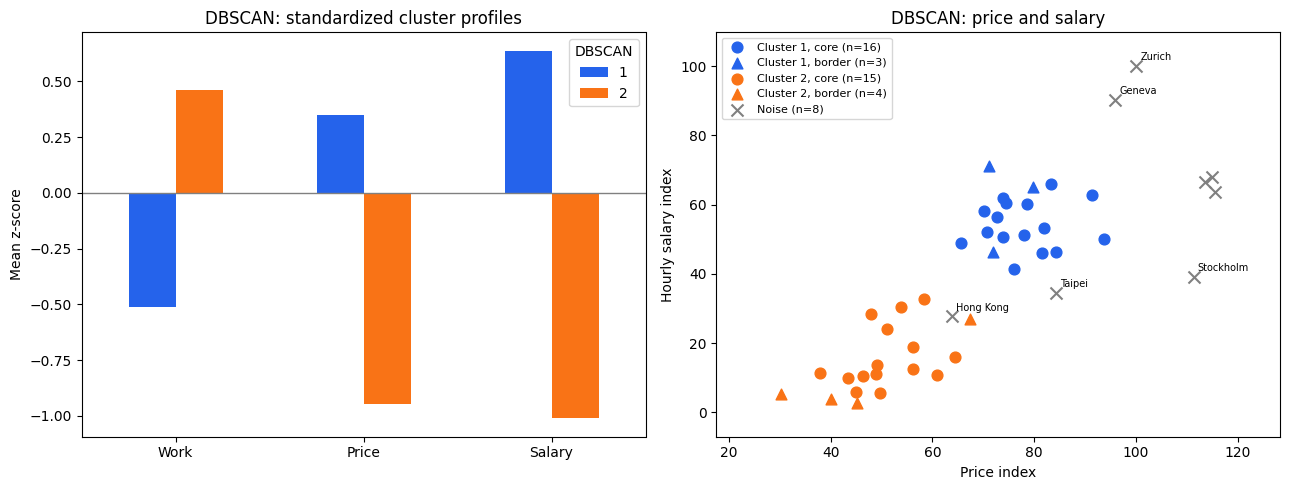

Число ядер, граничных и шумовых точек:
Point_type
core      31
noise      8
border     7


In [56]:
# Показываем назначения и типы точек; шум отображаем отдельно от кластеров.
# Цвет обозначает кластер, форма маркера — ядро, границу или шум.
# Price–Salary — проекция модели, построенной по трём признакам.
display(cities3.sort_values(['DBSCAN','City']).reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
prof3 = pd.DataFrame(X3, columns=features3).assign(DBSCAN=db_labels)
prof3 = prof3.loc[keep3].groupby('DBSCAN').mean()
prof3.T.plot.bar(ax=axes[0], rot=0, color=['#2563eb','#f97316'])
axes[0].axhline(0, color='grey', linewidth=1)
axes[0].set(title='DBSCAN: standardized cluster profiles', ylabel='Mean z-score')
for c, color in [(1,'#2563eb'),(2,'#f97316')]:
    for typ, marker in [('core','o'),('border','^')]:
        part = cities3[(cities3.DBSCAN==c)&(cities3.Point_type==typ)]
        axes[1].scatter(part.Price, part.Salary, c=color, marker=marker, s=60,
                        label=f'Cluster {c}, {typ} (n={len(part)})')
noise3 = cities3[cities3.DBSCAN==-1]
axes[1].scatter(noise3.Price, noise3.Salary, c='grey', marker='x', s=75, label=f'Noise (n={len(noise3)})')
for _, row in noise3[noise3.City.isin(['Geneva','Zurich','Hong_Kong','Taipei','Stockholm'])].iterrows():
    axes[1].annotate(row.City.replace('_',' '), (row.Price,row.Salary),
                     xytext=(3,4), textcoords='offset points', fontsize=7)
axes[1].set(title='DBSCAN: price and salary', xlabel='Price index', ylabel='Hourly salary index')
axes[1].margins(x=.15, y=.10)
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
print('Число ядер, граничных и шумовых точек:')
print(cities3.Point_type.value_counts().to_string())


### Интерпретация групп и шума

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Интерпретация |
|---|---:|---:|---:|---:|---|
| 1 | 19 | 1792,00 | 77,53 | 55,16 | Плотная группа с более высокими ценами и зарплатами и меньшим рабочим временем |
| 2 | 19 | 1959,21 | 50,12 | 14,79 | Плотная группа с более низкими ценами и зарплатами и большим рабочим временем |

В первую группу входят, например, Amsterdam, London и New York; во вторую — Athens, Bombay и Mexico City. Обе группы сохраняют основной экономический контраст из предыдущих работ.

**Шум:** Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo и Zurich. Это 8 городов, не присоединённых к плотным группам при выбранных параметрах. Они неоднородны: Geneva, Helsinki, Oslo, Stockholm, Tokyo и Zurich имеют высокие индексы цен; Hong Kong отличается большим рабочим временем, а Taipei также сочетанием рабочего времени и цен. Отсутствие собственной достаточно плотной группы нельзя трактовать как общую экономическую характеристику всех восьми городов. Средние по шуму приведены только описательно.

### Чувствительность и сравнение методов


In [57]:
# Показываем соседние параметры, включая слияние в один кластер и рост доли шума.
nearby3 = db_grid[db_grid.eps.between(.65,.95)]
display(nearby3.round(4))
print('Количество кластеров в окрестности параметров:')
display(nearby3.pivot(index='eps', columns='min_samples', values='clusters'))
print('Количество шумовых точек в той же окрестности:')
display(nearby3.pivot(index='eps', columns='min_samples', values='noise'))

# Сравниваем метрики на одних и тех же 38 не-шумовых городах.
# Силуэт DBSCAN на подвыборке нельзя напрямую сравнивать с силуэтом по всем 46 городам.
km3 = KMeans(n_clusters=2, n_init=50, random_state=42).fit_predict(X3)
ward3 = cut_tree(linkage(X3, method='ward'), n_clusters=2).ravel()
comparison3 = []
for name, lab in [('Ward',ward3),('K-means',km3),('DBSCAN',db_labels)]:
    full_sil = silhouette_score(X3,lab) if name!='DBSCAN' else np.nan
    common_sil = silhouette_score(X3[keep3],lab[keep3])
    comparison3.append({'Method':name,'Clusters':len(set(lab)-{-1}),
                        'Noise':int((lab==-1).sum()), 'Coverage':float((lab!=-1).mean()),
                        'Silhouette_all_46':full_sil,'Silhouette_common_38':common_sil,
                        'ARI_vs_DBSCAN_common':adjusted_rand_score(db_labels[keep3],lab[keep3])})
comparison3 = pd.DataFrame(comparison3)
display(comparison3.round(4))
cities3.to_csv('lab3_dbscan_clusters.csv', index=False, encoding='utf-8-sig')
db_summary.to_csv('lab3_dbscan_profiles.csv', encoding='utf-8-sig')
db_grid.to_csv('lab3_dbscan_parameter_grid.csv', index=False, encoding='utf-8-sig')
comparison3.to_csv('labs_1_3_comparison.csv', index=False, encoding='utf-8-sig')


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
7,0.65,3,2,13,0.7174,0.5454,"[16, 17]"
8,0.70,3,2,11,0.7609,0.5400,"[17, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
11,0.85,3,1,8,0.8261,NaN,[38]
12,0.90,3,1,8,0.8261,NaN,[38]
13,0.95,3,1,8,0.8261,NaN,[38]
38,0.65,4,3,15,0.6739,0.3793,"[16, 4, 11]"
39,0.70,4,3,11,0.7609,0.3565,"[17, 4, 14]"
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"


Количество кластеров в окрестности параметров:


min_samples,3,4,5,6
eps,,,,
0.65,2,3,2,2
0.70,2,3,3,2
0.75,2,2,2,3
0.80,2,2,2,2
0.85,1,1,2,2
0.90,1,1,2,2
0.95,1,1,2,2


Количество шумовых точек в той же окрестности:


min_samples,3,4,5,6
eps,,,,
0.65,13,15,25,27
0.70,11,11,21,24
0.75,8,9,9,16
0.80,8,8,9,12
0.85,8,8,9,11
0.90,8,8,8,9
0.95,8,8,8,9


,Method,Clusters,Noise,Coverage,Silhouette_all_46,Silhouette_common_38,ARI_vs_DBSCAN_common
0,Ward,2,0,1.0000,0.4705,0.512,1.0
1,K-means,2,0,1.0000,0.4705,0.512,1.0
2,DBSCAN,2,8,0.8261,NaN,0.512,1.0


### Вывод по DBSCAN и сравнение трёх работ

При **eps = 0,80, min_samples = 4** DBSCAN выделил **2 кластера по 19 городов** и **8 шумовых наблюдений**. Силуэт без шума — **0,5120**, покрытие — **82,61%**. Группы интерпретируются как два различных сочетания цен, почасовых зарплат и рабочего времени. Шумовые города перечислены и разобраны отдельно.

**Чувствительность существенна:** при min_samples = 4 и eps = 0,75 ещё сохраняются две группы (9 шумовых точек), но при eps = 0,85 группы уже сливаются в одну (8 шумовых точек). Следовательно, результат не следует представлять как единственное устойчивое число естественных групп; он зависит от принятого масштаба плотности.

| Метод | Группы | Шум | Покрытие 46 городов | Силуэт на всех 46 | Силуэт на общих 38 |
|---|---:|---:|---:|---:|---:|
| Ward | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| k-means | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| DBSCAN | 2: 19 и 19 | 8 | 82,61% | не рассчитывается | 0,5120 |

На общей подвыборке 38 городов **все три разбиения совпадают (ARI = 1)**. Более высокий силуэт DBSCAN по сравнению с 0,4705 объясняется в данном сравнении выбором подмножества объектов, поэтому не доказывает превосходство DBSCAN. Для общей сегментации всех полных наблюдений Ward и k-means удобнее; DBSCAN дополнительно показывает города, не включённые в плотные группы при выбранных параметрах.
